<a href="https://colab.research.google.com/github/jinatyeasmin/MCA-DATA-SCIENCE/blob/main/Mobile-sales/Mobile_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Load and clean the data


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('MobSales.csv')

text_cols = ['Brands', 'Models', 'Colors', 'Mobile']
for c in text_cols:
    df[c] = df[c].str.strip()

df['Memory'] = pd.to_numeric(df['Memory'], errors='coerce')
df = df.dropna(subset=['Memory']).reset_index(drop=True)

print('Rows, Columns:', df.shape)
df.head()

Rows, Columns: (3113, 11)


,Brands,Models,Colors,Mobile,Memory,Storage,Selling Price,Original Price,Discount,Rating,Good Product
0,SAMSUNG,GALAXY M31S,Mirage Black,SAMSUNG GALAXY M31S,8.0,128,19330,20999,1669,4.3,1
1,Nokia,3.2,Steel,Nokia 3.2,2.0,16,10199,10199,0,3.8,0
2,realme,C2,Diamond Black,realme C2,2.0,64,6999,7999,1000,4.4,1
3,Infinix,Note 5,Ice Blue,Infinix Note 5,4.0,64,12999,12999,0,4.2,1
4,Apple,iPhone 11,Black,Apple iPhone 11,4.0,64,49900,49900,0,4.6,1


## Q1: Which mobile brand has the highest number of models?

Brands
SAMSUNG    719
Apple      387
realme     327
OPPO       260
Nokia      213
Xiaomi     198
Infinix    151
GIONEE     129
vivo       124
Lenovo     120
Name: count, dtype: int64

Brand with the most models: SAMSUNG (719 models)


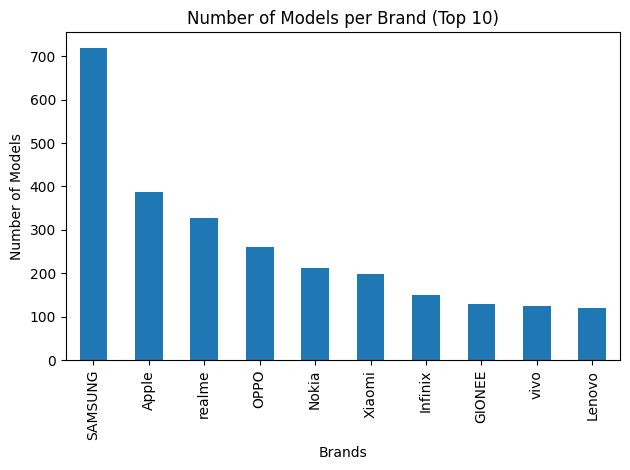

In [ ]:
brand_counts = df['Brands'].value_counts()
print(brand_counts.head(10))

top_brand = brand_counts.idxmax()
print(f"\nBrand with the most models: {top_brand} ({brand_counts.max()} models)")

brand_counts.head(10).plot(kind='bar', title='Number of Models per Brand (Top 10)')
plt.ylabel('Number of Models')
plt.tight_layout()
plt.show()

## Q2: Top 10 mobile models based on Selling Price

                 Models   Brands  Selling Price
2031  iPhone 13 Pro Max    Apple         179900
902   iPhone 13 Pro Max    Apple         179900
1184  iPhone 13 Pro Max    Apple         179900
830   iPhone 13 Pro Max    Apple         179900
1078  iPhone 13 Pro Max    Apple         179900
812   iPhone 13 Pro Max    Apple         179900
798   iPhone 13 Pro Max    Apple         179900
1284  iPhone 13 Pro Max    Apple         179900
323   iPhone 13 Pro Max    Apple         179900
922           Fold 2 5G  SAMSUNG         169999


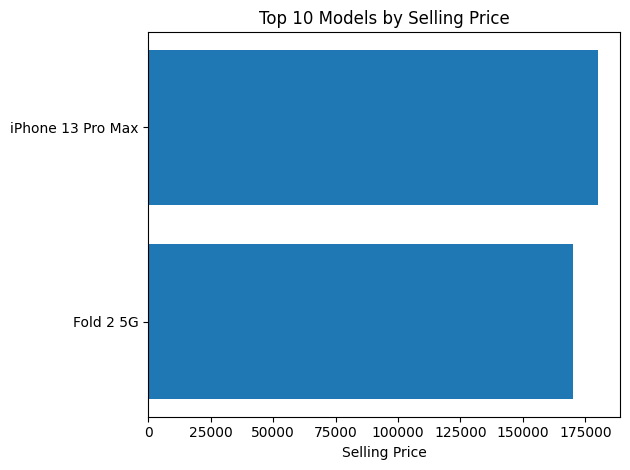

In [ ]:
top10_price = df[['Models', 'Brands', 'Selling Price']].sort_values('Selling Price', ascending=False).head(10)
print(top10_price)

plt.barh(top10_price['Models'], top10_price['Selling Price'])
plt.xlabel('Selling Price')
plt.title('Top 10 Models by Selling Price')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Q3: Average selling price of mobiles for each brand

Brands
Apple           81985.560724
Google Pixel    61391.862069
IQOO            37190.000000
HTC             28314.381818
SAMSUNG         24296.248957
vivo            23866.241935
ASUS            20326.915254
LG              19323.181818
OPPO            18560.488462
Xiaomi          16941.909091
POCO            16870.621622
realme          16396.535168
Motorola        16357.466667
Infinix         11092.178808
Lenovo          10105.383333
Nokia            9428.657277
GIONEE           7135.093023
Name: Selling Price, dtype: float64


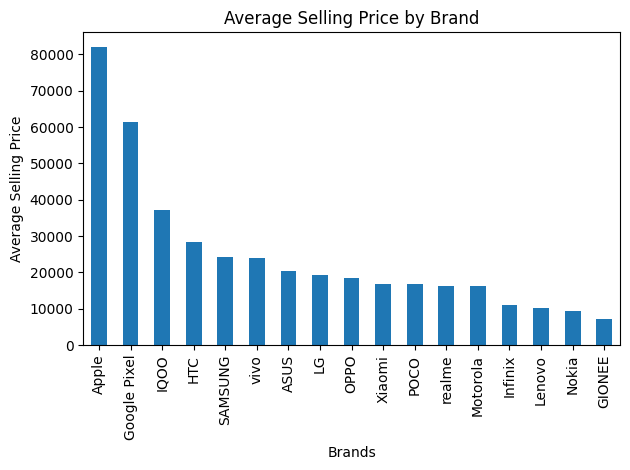

In [ ]:
avg_price_brand = df.groupby('Brands')['Selling Price'].mean().sort_values(ascending=False)
print(avg_price_brand)

avg_price_brand.plot(kind='bar', title='Average Selling Price by Brand')
plt.ylabel('Average Selling Price')
plt.tight_layout()
plt.show()

## Q4: Which mobile brand offers the highest average discount?

Brands
Motorola        4323.895238
IQOO            3800.000000
LG              3044.595960
Apple           2931.811370
POCO            2614.864865
SAMSUNG         2535.781641
OPPO            2050.776923
vivo            1696.661290
realme          1441.599388
ASUS            1258.474576
Infinix          925.907285
Xiaomi           911.343434
Nokia            745.732394
GIONEE           683.519380
Google Pixel     620.344828
Lenovo           268.891667
HTC                0.000000
Name: Discount, dtype: float64

Brand with highest average discount: Motorola (4323.90)


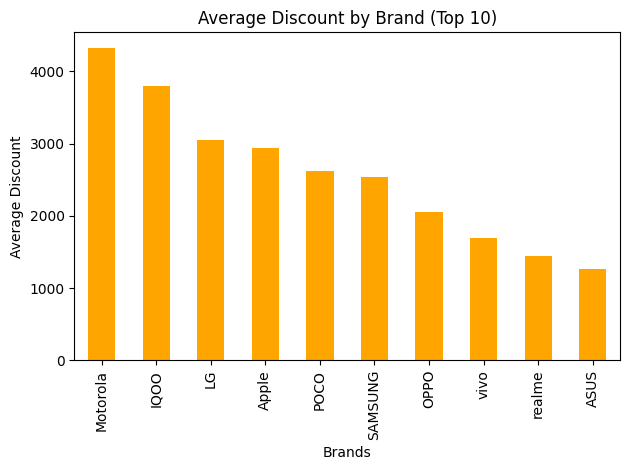

In [ ]:
avg_discount_brand = df.groupby('Brands')['Discount'].mean().sort_values(ascending=False)
print(avg_discount_brand)

top_discount_brand = avg_discount_brand.idxmax()
print(f"\nBrand with highest average discount: {top_discount_brand} ({avg_discount_brand.max():.2f})")

avg_discount_brand.head(10).plot(kind='bar', title='Average Discount by Brand (Top 10)', color='orange')
plt.ylabel('Average Discount')
plt.tight_layout()
plt.show()

## Q5: Brands with the highest average rating, and how their average price compares

              Avg_Rating  Avg_Selling_Price
Brands                                     
Apple           4.519380       81985.560724
Google Pixel    4.506897       61391.862069
IQOO            4.400000       37190.000000
POCO            4.385135       16870.621622
realme          4.381040       16396.535168
vivo            4.370968       23866.241935
Xiaomi          4.301515       16941.909091
OPPO            4.295000       18560.488462
Infinix         4.276821       11092.178808
SAMSUNG         4.208067       24296.248957


/tmp/ipykernel_1082/2313616638.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(top.index, rotation=90)


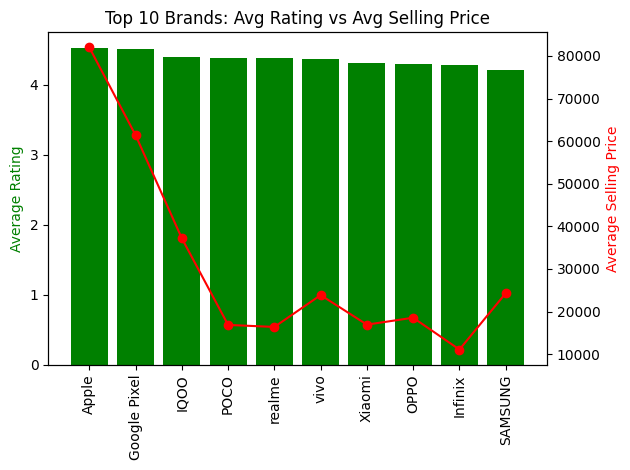

In [ ]:
brand_summary = df.groupby('Brands').agg(
    Avg_Rating=('Rating', 'mean'),
    Avg_Selling_Price=('Selling Price', 'mean')
).sort_values('Avg_Rating', ascending=False)

print(brand_summary.head(10))

fig, ax1 = plt.subplots()
top = brand_summary.head(10)
ax1.bar(top.index, top['Avg_Rating'], color='green')
ax1.set_ylabel('Average Rating', color='green')
ax1.set_xticklabels(top.index, rotation=90)

ax2 = ax1.twinx()
ax2.plot(top.index, top['Avg_Selling_Price'], color='red', marker='o')
ax2.set_ylabel('Average Selling Price', color='red')

plt.title('Top 10 Brands: Avg Rating vs Avg Selling Price')
plt.tight_layout()
plt.show()

## Q6: How does storage capacity affect average selling price?

   Storage  Avg Selling Price
0      1TB           171906.0
1      2GB             2037.0
2      4GB             5665.0
3      8GB             8094.0
4     10GB             1599.0
5     16GB            12090.0
6     32GB            14399.0
7     48GB             3024.0
8     64GB            21170.0
9    100GB             2724.0
10   128GB            30238.0
11   129GB            22427.0
12   130GB            22550.0
13   140GB             5999.0
14   153GB             1549.0
15   256GB            66900.0
16   512GB           121471.0


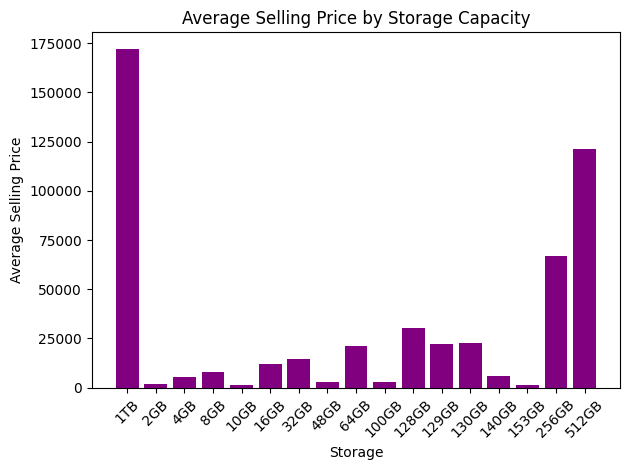

In [ ]:
storage_price = df.groupby('Storage')['Selling Price'].mean().sort_index()
labels = ['1TB' if s == 1 else f'{int(s)}GB' for s in storage_price.index]

print(pd.DataFrame({'Storage': labels, 'Avg Selling Price': storage_price.values.round(0)}))

plt.bar(labels, storage_price.values, color='purple')
plt.xlabel('Storage')
plt.ylabel('Average Selling Price')
plt.title('Average Selling Price by Storage Capacity')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Q7: Which models give the highest discount amount, and what % of the original price is that?

In [ ]:
df['Discount_Percent'] = (df['Discount'] / df['Original Price']) * 100

top_discount_models = df[['Models', 'Brands', 'Discount', 'Discount_Percent']]\
    .sort_values('Discount', ascending=False).head(10)

print(top_discount_models)

             Models    Brands  Discount  Discount_Percent
589            Razr  Motorola     75000         50.000333
710            Razr  Motorola     75000         50.000333
847         Razr 5G  Motorola     60000         40.000267
306             ROG      ASUS     57500         68.453196
507            Wing        LG     50001         62.501250
2631           Wing        LG     50001         62.501250
1427  iPhone XS Max     Apple     45901         36.750200
910   iPhone XS Max     Apple     45901         36.750200
410   iPhone XS Max     Apple     45901         36.750200
1481            G8X        LG     42010         60.014286


##Q8. Which combination of Memory + Storage gives the best balance of price and rating?



In [ ]:
combo = df.groupby(['Memory', 'Storage']).agg(
    Avg_Price=('Selling Price', 'mean'),
    Avg_Rating=('Rating', 'mean'),
    Count=('Models', 'count')
).reset_index()

combo = combo[combo['Count'] >= 5]

combo['Balance_Score'] = combo['Avg_Rating'] / (combo['Avg_Price'] / 1000)
combo_sorted = combo.sort_values('Balance_Score', ascending=False)

print(combo_sorted.head(10))

    Memory  Storage    Avg_Price  Avg_Rating  Count  Balance_Score
50    14.0        2  1456.368421    4.184211     19       2.873044
22     4.0        4  1830.857143    4.146429     28       2.264747
51    14.0       16  1945.400000    4.200000      5       2.158939
21     4.0        2  2151.166667    4.216667      6       1.960177
66    32.0        2  2605.750000    4.137500      8       1.587835
38     8.0       16  2946.454545    4.054545     11       1.376076
74    64.0      128  3451.833333    3.891667     12       1.127420
61    16.0       32  3643.600000    3.860000      5       1.059392
80   512.0        4  5606.243243    3.800000     37       0.677816
87   768.0        4  6854.833333    3.766667      6       0.549491


## Q9: Top 10 mobile models by 'value for money'


In [ ]:
def normalize(series):
    return (series - series.min()) / (series.max() - series.min())

df['Price_Score']    = 1 - normalize(df['Selling Price'])   # lower price = better
df['Discount_Score'] = normalize(df['Discount'])            # bigger discount = better
df['Storage_Score']  = normalize(df['Storage'])             # more storage = better
df['Memory_Score']   = normalize(df['Memory'])              # more RAM = better
df['Rating_Score']   = normalize(df['Rating'])              # higher rating = better

df['Value_Score'] = df[['Price_Score', 'Discount_Score', 'Storage_Score',
                        'Memory_Score', 'Rating_Score']].mean(axis=1)

top10_value = df[['Models', 'Brands', 'Selling Price', 'Discount', 'Storage', 'Memory', 'Rating', 'Value_Score']]\
    .sort_values('Value_Score', ascending=False).head(10)

print(top10_value)

                  Models   Brands  Selling Price  Discount  Storage  Memory  \
1794      Guru Plus B110  SAMSUNG           1700         0      512   512.0   
650                A269i   Lenovo           5499         0      512   512.0   
730      Galaxy S10 Lite  SAMSUNG          45999      5001      512     8.0   
32         Galaxy Note 9  SAMSUNG          49999         0      512     8.0   
976        Galaxy Core 2  SAMSUNG           5920         0        4   768.0   
1178       Galaxy Core 2  SAMSUNG           5940         0        4   768.0   
566   Optimus L7 II Dual       LG          13299         0        4   768.0   
2941            Asha 311    Nokia           5999       880      140   512.0   
772      Galaxy S10 Lite  SAMSUNG          49999         0      512     8.0   
306                  ROG     ASUS          26499     57500      128     8.0   

      Rating  Value_Score  
1794     4.2     0.692482  
650      3.7     0.651198  
730      4.5     0.545810  
32       4.6     0

## Q10: What factors are most strongly related to a mobile being a 'Good Product'?


Rating            0.730646
Memory           -0.240195
Storage           0.222115
Original Price    0.183532
Selling Price     0.182979
Discount          0.053266
Name: Good Product, dtype: float64


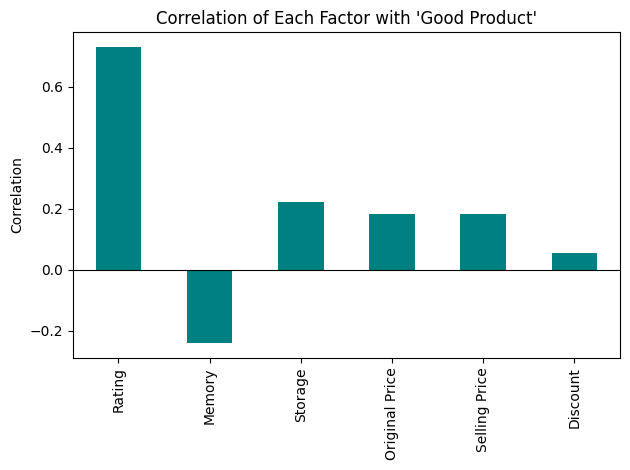

In [ ]:
numeric_cols = ['Memory', 'Storage', 'Selling Price', 'Original Price', 'Discount', 'Rating', 'Good Product']
corr_with_good = df[numeric_cols].corr()['Good Product'].drop('Good Product').sort_values(key=abs, ascending=False)

print(corr_with_good)

corr_with_good.plot(kind='bar', title="Correlation of Each Factor with 'Good Product'", color='teal')
plt.ylabel('Correlation')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### Interpreting Q10
- A correlation close to **+1** means: as that factor goes up, the mobile is more likely to be a 'Good Product'.
- A correlation close to **-1** means: as that factor goes up, the mobile is less likely to be a 'Good Product'.
- Values close to **0** mean little to no relationship.
